<a href="https://colab.research.google.com/github/Uriels28/Hands-on-5-Support-Vector-Machines/blob/main/Tutorial_SVM_scikit_learn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# 1. Fundamentos teóricos de la técnica SVM

## ¿Qué es una SVM?
Una **Máquina de Vectores de Soporte** (*Support Vector Machine*, SVM) es un algoritmo de **aprendizaje supervisado** que sirve para **clasificación** (y también para regresión, llamada SVR y para detección de anomalías). Fue propuesta por Vapnik y colaboradores en los años 90.

## Idea central
Dado un conjunto de datos etiquetados de dos clases, existen **infinitos hiperplanos** que podrían separarlas (si son linealmente separables). La SVM elige **el hiperplano que maximiza el margen**, es decir, la distancia entre el hiperplano y los puntos más cercanos de cada clase.

## Conceptos clave

| Concepto | Descripción |
|---|---|
| **Hiperplano** | Frontera de decisión. En 2D es una recta, en 3D un plano, en nD un hiperplano. |
| **Margen** | Distancia entre el hiperplano y las observaciones más cercanas. La SVM lo maximiza. |
| **Vectores de soporte** | Puntos de entrenamiento que quedan sobre el margen (o dentro de él). Son los **únicos** que definen el hiperplano; el resto de puntos podría eliminarse sin cambiar el modelo. |
| **Margen duro (*hard margin*)** | Exige separación perfecta. Solo funciona con datos linealmente separables y es sensible a *outliers*. |
| **Margen blando (*soft margin*)** | Permite algunos errores o puntos dentro del margen, controlado por el parámetro **C**. |
| **Truco del kernel (*kernel trick*)** | Permite separar datos **no lineales** proyectándolos implícitamente a un espacio de mayor dimensión, sin calcular explícitamente esa proyección. |

## Hiperparámetros principales en scikit-learn (`SVC`)

- **`C`**: penalización por errores de clasificación.
  - `C` grande → margen estrecho, pocos errores en entrenamiento (riesgo de *overfitting*).
  - `C` pequeño → margen amplio, tolera más errores (riesgo de *underfitting*).
- **`kernel`**: función de transformación (`'linear'`, `'poly'`, `'rbf'`, `'sigmoid'`).
- **`gamma`**: en kernels `rbf`, `poly` y `sigmoid`, controla la influencia de cada punto de entrenamiento.
  - `gamma` grande → influencia local, frontera muy ajustada (riesgo de *overfitting*).
  - `gamma` pequeño → influencia amplia, frontera más suave.
- **`degree`**: grado del polinomio (solo kernel `poly`).

## Ventajas y desventajas

|  Ventajas |  Desventajas |
|---|---|
| Eficaz en espacios de alta dimensión | Costoso en datasets muy grandes (≈ O(n²) a O(n³)) |
| Funciona bien con pocos datos | Requiere escalar las variables |
| Versátil gracias a los kernels | Sensible a la elección de `C`, `kernel` y `gamma` |
| Usa solo los vectores de soporte (memoria eficiente) | No entrega probabilidades de forma nativa |
| Solución global (problema convexo) | Poco interpretable con kernels no lineales |

---
# 2. Modelo matemático

> ℹ Se presenta el modelo **sin desarrollo analítico** (no se deducen las ecuaciones, solo se enuncian).

## 2.1 Función de decisión (caso lineal)

Dado un vector de características $\mathbf{x} \in \mathbb{R}^n$, la SVM define un hiperplano:

$$
f(\mathbf{x}) = \mathbf{w}^\top \mathbf{x} + b = 0
$$

donde $\mathbf{w}$ es el vector normal al hiperplano y $b$ es el sesgo (*bias*). La clase predicha es:

$$
\hat{y} = \operatorname{sign}\left(\mathbf{w}^\top \mathbf{x} + b\right), \qquad y \in \{-1, +1\}
$$

## 2.2 Margen

El ancho del margen entre las dos clases es:

$$
\text{margen} = \frac{2}{\lVert \mathbf{w} \rVert}
$$

Maximizar el margen equivale a **minimizar** $\lVert \mathbf{w} \rVert$.

## 2.3 Problema de optimización (forma primal)

**Margen duro** (datos linealmente separables):

$$
\min_{\mathbf{w},\,b} \; \frac{1}{2}\lVert \mathbf{w} \rVert^2
\quad \text{sujeto a} \quad y_i\left(\mathbf{w}^\top \mathbf{x}_i + b\right) \ge 1, \;\; \forall i
$$

**Margen blando** (permite errores mediante variables de holgura $\xi_i$):

$$
\min_{\mathbf{w},\,b,\,\boldsymbol{\xi}} \; \frac{1}{2}\lVert \mathbf{w} \rVert^2 + C \sum_{i=1}^{m} \xi_i
\quad \text{sujeto a} \quad y_i\left(\mathbf{w}^\top \mathbf{x}_i + b\right) \ge 1 - \xi_i, \;\; \xi_i \ge 0
$$

- $\xi_i = 0$: punto bien clasificado fuera del margen.
- $0 < \xi_i \le 1$: punto dentro del margen pero bien clasificado.
- $\xi_i > 1$: punto mal clasificado.

## 2.4 Función de pérdida equivalente (*Hinge loss*)

El problema anterior es equivalente a minimizar:

$$
J(\mathbf{w}, b) = \frac{1}{2}\lVert \mathbf{w} \rVert^2 + C \sum_{i=1}^{m} \max\left(0,\; 1 - y_i\left(\mathbf{w}^\top \mathbf{x}_i + b\right)\right)
$$

## 2.5 Forma dual y *kernel trick*

Resolviendo el problema dual (con multiplicadores de Lagrange $\alpha_i$), la función de decisión se expresa solo en términos de productos entre puntos:

$$
f(\mathbf{x}) = \operatorname{sign}\left( \sum_{i \in SV} \alpha_i \, y_i \, K(\mathbf{x}_i, \mathbf{x}) + b \right), \qquad 0 \le \alpha_i \le C
$$

Solo los **vectores de soporte** (SV) tienen $\alpha_i > 0$. La función $K(\mathbf{x}_i, \mathbf{x}_j) = \phi(\mathbf{x}_i)^\top \phi(\mathbf{x}_j)$ se llama **kernel**.

## 2.6 Kernels más usados

| Kernel | Fórmula | Hiperparámetros |
|---|---|---|
| Lineal | $K(\mathbf{x}, \mathbf{z}) = \mathbf{x}^\top \mathbf{z}$ | — |
| Polinomial | $K(\mathbf{x}, \mathbf{z}) = (\gamma\, \mathbf{x}^\top \mathbf{z} + r)^d$ | $\gamma, r, d$ |
| RBF (Gaussiano) | $K(\mathbf{x}, \mathbf{z}) = \exp\left(-\gamma \lVert \mathbf{x} - \mathbf{z} \rVert^2\right)$ | $\gamma$ |
| Sigmoide | $K(\mathbf{x}, \mathbf{z}) = \tanh(\gamma\, \mathbf{x}^\top \mathbf{z} + r)$ | $\gamma, r$ |

## 2.7 Clasificación multiclase
La SVM es binaria por naturaleza. Para $k > 2$ clases, `SVC` de scikit-learn usa la estrategia **uno contra uno** (*one-vs-one*): entrena $\frac{k(k-1)}{2}$ clasificadores binarios y decide por votación.

---
# 3. Contraste: SVM vs. Perceptrón

Ambos son **clasificadores lineales** que buscan un hiperplano $\mathbf{w}^\top \mathbf{x} + b = 0$, pero difieren en **qué hiperplano eligen** y **cómo lo encuentran**.

| Característica | **Perceptrón** | **SVM** |
|---|---|---|
| **Criterio de optimización** | Minimizar errores de clasificación (actualiza cuando se equivoca) | Maximizar el **margen** entre clases |
| **Función de pérdida** | *Perceptron loss*: $\max(0, -y f(\mathbf{x}))$ | *Hinge loss*: $\max(0, 1 - y f(\mathbf{x}))$ |
| **Solución** | **No única**: depende del orden de los datos y de la inicialización | **Única** (problema convexo con óptimo global) |
| **Generalización** | Puede quedar muy cerca de algunos puntos | El margen máximo suele generalizar mejor |
| **Datos no separables linealmente** | **No converge** (oscila indefinidamente) | Margen blando (`C`) y kernels |
| **No linealidad** | No la maneja (el perceptrón simple) | **Kernel trick** (RBF, polinomial, etc.) |
| **Regularización** | No incluida por defecto | Incluida de forma natural ($\lVert \mathbf{w} \rVert^2$ y `C`) |
| **Qué puntos influyen** | Los puntos mal clasificados durante el entrenamiento | Solo los **vectores de soporte** |
| **Costo de entrenamiento** | Muy bajo, entrenamiento *online* | Mayor (programación cuadrática) |
| **Relación histórica** | Antecesor de las redes neuronales | Evolución con teoría de aprendizaje estadístico (Vapnik) |

## Intuición visual

- El **perceptrón** se detiene en cuanto encuentra *cualquier* recta que separe las clases.
- La **SVM** continúa hasta encontrar la recta **más alejada posible** de ambas clases.

> 🔎 En la sección **4.9** se comparan ambos modelos en la práctica con código.

---
# 4. Pipeline de Machine Learning con SVM

Un *pipeline* de Machine Learning es la secuencia de etapas que transforma datos crudos en un modelo útil:

```
Problema → Datos → EDA → Preparación → Modelo → Ajuste → Evaluación → Despliegue
```

Antes de empezar, importamos todas las librerías que necesitaremos.

In [10]:
# Importamos NumPy para realizar operaciones numéricas sobre arreglos
import numpy as np
# Importamos pandas para manejar datos tabulares mediante DataFrames
import pandas as pd
# Importamos pyplot de matplotlib para crear gráficos
import matplotlib.pyplot as plt
# Importamos seaborn para gráficos estadísticos más atractivos
import seaborn as sns
# Importamos display para mostrar tablas de forma bonita en el notebook
from IPython.display import display
# Importamos load_iris (dataset de ejemplo) y make_moons (dataset sintético no lineal)
from sklearn.datasets import load_iris, make_moons
# Importamos funciones para dividir datos y para búsqueda de hiperparámetros con validación cruzada
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
# Importamos StandardScaler para estandarizar las variables (media 0, desviación 1)
from sklearn.preprocessing import StandardScaler
# Importamos SVC, la implementación de SVM para clasificación en scikit-learn
from sklearn.svm import SVC
# Importamos el Perceptrón para compararlo con la SVM
from sklearn.linear_model import Perceptron
# Importamos las métricas de evaluación y la visualización de la matriz de confusión
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
# Importamos Pipeline para encadenar escalado y modelo en un solo objeto
from sklearn.pipeline import Pipeline
# Importamos joblib para guardar el modelo entrenado en un archivo
import joblib

# Fijamos el estilo visual de los gráficos de seaborn
sns.set_theme(style="whitegrid")
# Definimos una semilla para que los resultados sean reproducibles
SEED = 42
# Mostramos un mensaje de confirmación
print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


## 4.1 Definición del problema

**Problema:** clasificar flores del género *Iris* en una de tres especies (*setosa*, *versicolor*, *virginica*) a partir de cuatro medidas físicas.

- **Tipo de tarea:** clasificación supervisada multiclase.
- **Variables de entrada (X):** largo y ancho del sépalo y del pétalo (en cm).
- **Variable objetivo (y):** especie de la flor.
- **Métrica de éxito:** *accuracy*, *precision*, *recall* y *F1-score*.

## 4.2 Recolección de datos

En proyectos reales, los datos se obtienen de bases de datos, APIs, archivos CSV, sensores, etc. Aquí usaremos el dataset **Iris** (Fisher, 1936), incluido en scikit-learn, con 150 observaciones.

In [2]:
# Cargamos el dataset Iris; as_frame=True lo devuelve como DataFrame de pandas
iris = load_iris(as_frame=True)
# Extraemos el DataFrame completo (4 características + columna 'target')
df = iris.frame.copy()
# Creamos una columna con el nombre de la especie, mapeando 0,1,2 a los nombres reales
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
# Guardamos la lista de nombres de las características para usarla más adelante
feature_names = iris.feature_names
# Imprimimos las dimensiones del dataset (filas, columnas)
print("Dimensiones del dataset:", df.shape)
# Mostramos las 5 primeras filas para verificar que la carga fue correcta
display(df.head())

Dimensiones del dataset: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 4.3 Descripción y análisis del dataset (EDA)

El **Análisis Exploratorio de Datos** permite entender la estructura, calidad y relaciones de los datos antes de modelar. Revisamos: tipos de datos, valores nulos, estadísticas descriptivas, balance de clases, correlaciones y *scatter plots*.

In [3]:
# Mostramos información general: nombres de columnas, tipos de datos y valores no nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [4]:
# Contamos los valores nulos (faltantes) en cada columna
print("Valores nulos por columna:")
# Sumamos los nulos por columna e imprimimos el resultado
print(df.isnull().sum())
# Contamos filas duplicadas, que podrían sesgar el entrenamiento
print("\nFilas duplicadas:", df.duplicated().sum())

Valores nulos por columna:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Filas duplicadas: 1


In [5]:
# Calculamos estadísticas descriptivas (media, desviación, mínimo, cuartiles, máximo) de las características
display(df[feature_names].describe().round(2))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


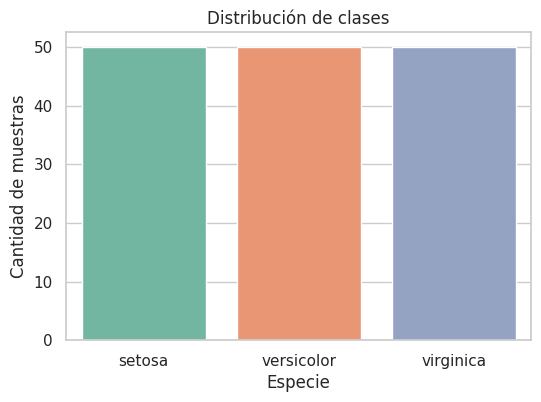

In [6]:
# Contamos cuántas observaciones hay de cada clase para verificar si el dataset está balanceado
conteo = df["species"].value_counts()
# Mostramos el conteo por clase
print(conteo)
# Creamos una figura de tamaño 6x4 pulgadas
plt.figure(figsize=(6, 4))
# Dibujamos un gráfico de barras con el número de muestras por especie
sns.countplot(data=df, x="species", hue="species", palette="Set2", legend=False)
# Colocamos el título del gráfico
plt.title("Distribución de clases")
# Etiquetamos el eje X
plt.xlabel("Especie")
# Etiquetamos el eje Y
plt.ylabel("Cantidad de muestras")
# Mostramos el gráfico
plt.show()

### Scatter plot (diagrama de dispersión)

El *scatter plot* permite ver visualmente si las clases son **separables**. Graficamos primero las dos variables del pétalo, y luego todas las combinaciones de variables con `pairplot`.

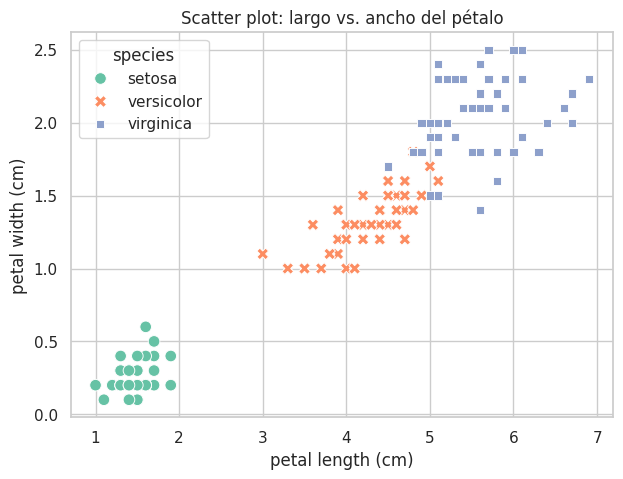

In [7]:
# Creamos una figura de tamaño 7x5 pulgadas
plt.figure(figsize=(7, 5))
# Dibujamos el scatter plot: largo del pétalo en X, ancho del pétalo en Y, color según la especie
sns.scatterplot(data=df, x="petal length (cm)", y="petal width (cm)",
                hue="species", style="species", palette="Set2", s=70)
# Colocamos el título del gráfico
plt.title("Scatter plot: largo vs. ancho del pétalo")
# Mostramos el gráfico
plt.show()

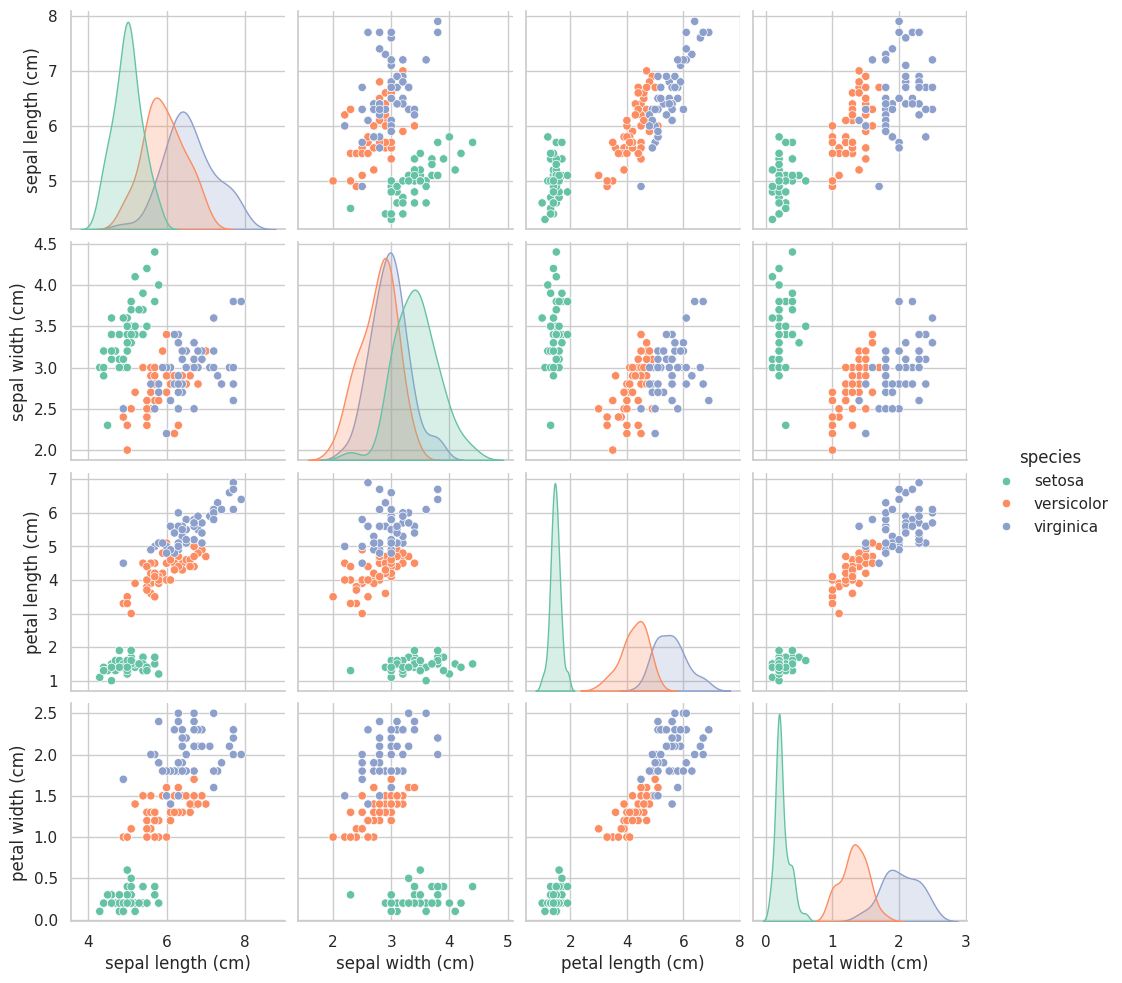

In [8]:
# Dibujamos una matriz de scatter plots (todas las combinaciones de variables); en la diagonal van histogramas/densidades
sns.pairplot(df, vars=feature_names, hue="species", palette="Set2", diag_kind="kde")
# Mostramos el gráfico
plt.show()

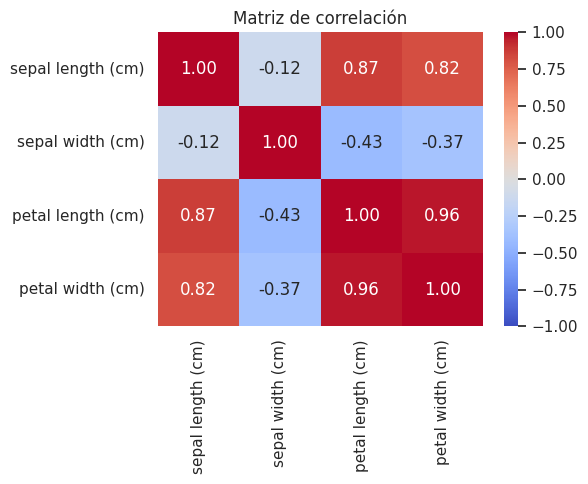

In [9]:
# Calculamos la matriz de correlación de Pearson entre las características
corr = df[feature_names].corr()
# Creamos una figura de tamaño 6x5 pulgadas
plt.figure(figsize=(6, 5))
# Dibujamos un mapa de calor con los valores de correlación anotados
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
# Colocamos el título del gráfico
plt.title("Matriz de correlación")
# Ajustamos los márgenes para que no se corten las etiquetas
plt.tight_layout()
# Mostramos el gráfico
plt.show()

###  Conclusiones del EDA

1.   Elemento de la lista
2.   Elemento de la lista



- El dataset tiene **150 muestras**, **4 variables numéricas**, sin valores nulos y con **clases balanceadas** (50 cada una).
- La clase **setosa** es **linealmente separable** de las otras dos.
- **Versicolor** y **virginica** se **solapan ligeramente**: aquí es donde una SVM con margen blando o kernel puede ayudar.
- Las variables del pétalo están **muy correlacionadas** entre sí y son las más discriminativas.
- Las variables tienen **escalas distintas**, por lo que conviene **estandarizarlas** (la SVM es sensible a la escala).

## 4.4 Preparación de datos

Dos pasos esenciales:

1. **Separar** en conjunto de entrenamiento y de prueba (para evaluar con datos que el modelo no vio).
2. **Escalar** las variables. La SVM calcula distancias; si una variable tiene escala mayor, dominaría el modelo.

>  **Importante:** el escalador se **ajusta solo con el set de entrenamiento** (`fit`) y luego se aplica al de prueba (`transform`). Así evitamos *data leakage* (fuga de información).

In [11]:
# Separamos las características (X): todas las columnas numéricas de entrada
X = df[feature_names]
# Separamos la variable objetivo (y): la columna con las clases codificadas como 0, 1, 2
y = df["target"]
# Dividimos en 80% entrenamiento y 20% prueba; stratify=y mantiene la proporción de clases en ambos conjuntos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
# Imprimimos el tamaño del conjunto de entrenamiento
print("Entrenamiento:", X_train.shape)
# Imprimimos el tamaño del conjunto de prueba
print("Prueba:", X_test.shape)

Entrenamiento: (120, 4)
Prueba: (30, 4)


In [12]:
# Creamos el objeto escalador que transformará cada variable a media 0 y desviación estándar 1
scaler = StandardScaler()
# Ajustamos el escalador SOLO con los datos de entrenamiento y los transformamos
X_train_s = scaler.fit_transform(X_train)
# Transformamos los datos de prueba usando la media y desviación calculadas en entrenamiento
X_test_s = scaler.transform(X_test)
# Verificamos que la media de cada columna de entrenamiento escalado sea ~0
print("Media tras escalar (entrenamiento):", X_train_s.mean(axis=0).round(2))
# Verificamos que la desviación estándar de cada columna sea ~1
print("Desv. estándar tras escalar (entrenamiento):", X_train_s.std(axis=0).round(2))

Media tras escalar (entrenamiento): [-0.  0.  0.  0.]
Desv. estándar tras escalar (entrenamiento): [1. 1. 1. 1.]


## 4.5 Selección y entrenamiento del modelo

Entrenamos primero dos SVM con hiperparámetros por defecto razonables para ver cómo se comportan:

- **SVM lineal** (`kernel='linear'`)
- **SVM con kernel RBF** (`kernel='rbf'`)

In [13]:
# Creamos una SVM con kernel lineal y penalización C=1.0
svm_lineal = SVC(kernel="linear", C=1.0, random_state=SEED)
# Entrenamos la SVM lineal con los datos de entrenamiento escalados
svm_lineal.fit(X_train_s, y_train)
# Creamos una SVM con kernel RBF; gamma='scale' calcula gamma automáticamente según los datos
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED)
# Entrenamos la SVM RBF con los mismos datos
svm_rbf.fit(X_train_s, y_train)
# Calculamos la exactitud (accuracy) de la SVM lineal sobre el set de prueba
acc_lineal = accuracy_score(y_test, svm_lineal.predict(X_test_s))
# Calculamos la exactitud de la SVM RBF sobre el set de prueba
acc_rbf = accuracy_score(y_test, svm_rbf.predict(X_test_s))
# Mostramos la exactitud de la SVM lineal
print(f"Accuracy SVM lineal: {acc_lineal:.3f}")
# Mostramos la exactitud de la SVM RBF
print(f"Accuracy SVM RBF   : {acc_rbf:.3f}")

Accuracy SVM lineal: 1.000
Accuracy SVM RBF   : 0.967


In [14]:
# Mostramos cuántos vectores de soporte tiene cada clase en la SVM lineal
print("Vectores de soporte por clase (lineal):", svm_lineal.n_support_)
# Mostramos el total de vectores de soporte de la SVM lineal
print("Total vectores de soporte (lineal):", svm_lineal.n_support_.sum(), "de", len(X_train_s), "muestras")
# Mostramos cuántos vectores de soporte tiene cada clase en la SVM RBF
print("Vectores de soporte por clase (RBF):", svm_rbf.n_support_)
# Mostramos el total de vectores de soporte de la SVM RBF
print("Total vectores de soporte (RBF):", svm_rbf.n_support_.sum(), "de", len(X_train_s), "muestras")

Vectores de soporte por clase (lineal): [ 2 11 10]
Total vectores de soporte (lineal): 23 de 120 muestras
Vectores de soporte por clase (RBF): [10 18 19]
Total vectores de soporte (RBF): 47 de 120 muestras


> Solo una fracción de los puntos de entrenamiento son **vectores de soporte**: son los únicos que definen la frontera de decisión.

## 4.6 Ajuste de hiperparámetros

El rendimiento de una SVM depende mucho de `C`, `kernel` y `gamma`. Usamos **`GridSearchCV`**, que prueba todas las combinaciones de una rejilla de valores usando **validación cruzada** (aquí 5 particiones o *folds*).

> La búsqueda se hace **solo con datos de entrenamiento**; el conjunto de prueba se reserva para la evaluación final.

In [15]:
# Definimos la rejilla de hiperparámetros a explorar
param_grid = {
    # Valores de penalización C: de un margen muy blando a uno muy estricto
    "C": [0.1, 1, 10, 100],
    # Valores de gamma (influencia de cada punto); 'scale' es el valor automático de sklearn
    "gamma": ["scale", 0.01, 0.1, 1],
    # Tipos de kernel a probar
    "kernel": ["linear", "rbf", "poly"],
}
# Creamos el buscador: modelo base SVC, rejilla, validación cruzada de 5 folds y métrica accuracy
grid = GridSearchCV(SVC(random_state=SEED), param_grid, cv=5, scoring="accuracy", n_jobs=-1)
# Ejecutamos la búsqueda entrenando todas las combinaciones con los datos de entrenamiento escalados
grid.fit(X_train_s, y_train)
# Mostramos la mejor combinación de hiperparámetros encontrada
print("Mejores hiperparámetros:", grid.best_params_)
# Mostramos la exactitud media de validación cruzada obtenida con esa combinación
print(f"Mejor accuracy (validación cruzada): {grid.best_score_:.3f}")

Mejores hiperparámetros: {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}
Mejor accuracy (validación cruzada): 0.983


In [16]:
# Convertimos los resultados de la búsqueda en un DataFrame para analizarlos
resultados = pd.DataFrame(grid.cv_results_)
# Seleccionamos solo las columnas relevantes para la lectura
columnas = ["param_kernel", "param_C", "param_gamma", "mean_test_score", "std_test_score", "rank_test_score"]
# Ordenamos por ranking (mejor primero) y mostramos las 8 mejores combinaciones
display(resultados[columnas].sort_values("rank_test_score").head(8).reset_index(drop=True))

,param_kernel,param_C,param_gamma,mean_test_score,std_test_score,rank_test_score
0,rbf,1.0,0.1,0.983333,0.033333,1
1,linear,0.1,scale,0.975000,0.033333,2
2,linear,0.1,0.1,0.975000,0.033333,2
3,linear,0.1,0.01,0.975000,0.033333,2
4,linear,1.0,scale,0.975000,0.020412,2
5,linear,1.0,0.01,0.975000,0.020412,2
6,linear,1.0,0.1,0.975000,0.020412,2
7,linear,0.1,1,0.975000,0.033333,2


## 4.7 Evaluación del modelo (métricas)

Evaluamos el **mejor modelo** sobre el conjunto de **prueba** (datos nunca vistos). Métricas:

| Métrica | Fórmula | Interpretación |
|---|---|---|
| **Accuracy** | $\dfrac{TP+TN}{TP+TN+FP+FN}$ | Proporción total de aciertos |
| **Precision** | $\dfrac{TP}{TP+FP}$ | De lo que predije como clase X, ¿cuánto era realmente X? |
| **Recall** | $\dfrac{TP}{TP+FN}$ | De lo que realmente era X, ¿cuánto detecté? |
| **F1-score** | $2\cdot\dfrac{P \cdot R}{P+R}$ | Media armónica de precision y recall |

La **matriz de confusión** muestra cuántas muestras de cada clase real fueron predichas en cada clase.

In [17]:
# Obtenemos el mejor modelo, ya reentrenado por GridSearchCV con todos los datos de entrenamiento
mejor_modelo = grid.best_estimator_
# Predecimos las clases del conjunto de prueba escalado
y_pred = mejor_modelo.predict(X_test_s)
# Calculamos la exactitud global en el conjunto de prueba
acc = accuracy_score(y_test, y_pred)
# Mostramos la exactitud con 3 decimales
print(f"Accuracy en prueba: {acc:.3f}\n")
# Mostramos el reporte con precision, recall, F1 y soporte por cada clase
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy en prueba: 0.967

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



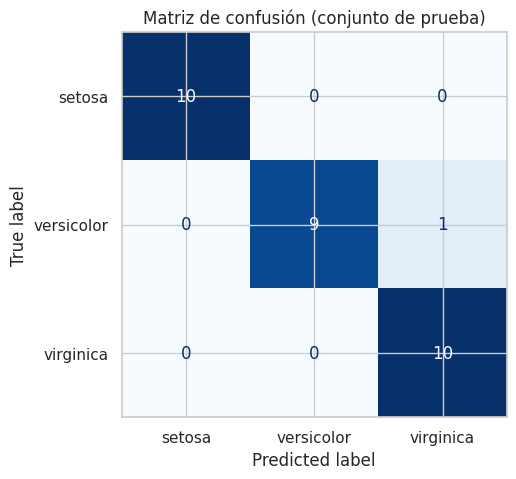

In [18]:
# Calculamos la matriz de confusión comparando etiquetas reales con las predichas
cm = confusion_matrix(y_test, y_pred)
# Creamos el objeto de visualización indicando los nombres de las clases
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
# Creamos una figura y un eje de tamaño 5x5 pulgadas
fig, ax = plt.subplots(figsize=(5, 5))
# Dibujamos la matriz de confusión con escala de azules sobre el eje creado
disp.plot(cmap="Blues", ax=ax, colorbar=False)
# Colocamos el título del gráfico
plt.title("Matriz de confusión (conjunto de prueba)")
# Mostramos el gráfico
plt.show()

In [19]:
# Calculamos la exactitud con validación cruzada de 5 folds sobre TODO el dataset (usando un Pipeline para evitar fuga de datos)
scores = cross_val_score(Pipeline([("scaler", StandardScaler()), ("svm", SVC(**grid.best_params_))]), X, y, cv=5)
# Mostramos la exactitud obtenida en cada fold
print("Accuracy por fold:", scores.round(3))
# Mostramos la media y desviación estándar para estimar la estabilidad del modelo
print(f"Media: {scores.mean():.3f}  ±  {scores.std():.3f}")

Accuracy por fold: [0.967 1.    0.967 0.933 1.   ]
Media: 0.973  ±  0.025


## 4.8 Visualización de la frontera de decisión

Para poder **dibujar** la frontera necesitamos solo **2 variables**. Usamos las del pétalo (las más discriminativas) y comparamos una SVM **lineal** con una SVM **RBF**. Los puntos con círculo negro son los **vectores de soporte**.

In [20]:
# Definimos una función reutilizable que dibuja la frontera de decisión de un modelo en 2D
def plot_frontera(modelo, X2, y2, ax, titulo):
    # Calculamos el mínimo y máximo de la primera variable (con un margen de 1 unidad) para definir el área del gráfico
    x_min, x_max = X2[:, 0].min() - 1, X2[:, 0].max() + 1
    # Calculamos el mínimo y máximo de la segunda variable con el mismo margen
    y_min, y_max = X2[:, 1].min() - 1, X2[:, 1].max() + 1
    # Creamos una malla (grid) de puntos que cubre toda el área, con paso de 0.02
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    # Predecimos la clase de cada punto de la malla (aplanando la malla a una lista de puntos)
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()])
    # Reorganizamos las predicciones con la misma forma que la malla
    Z = Z.reshape(xx.shape)
    # Pintamos las regiones de decisión con colores suaves
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="Set2")
    # Dibujamos los puntos de datos coloreados según su clase real
    ax.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="Set2", edgecolor="k", s=40)
    # Si el modelo tiene vectores de soporte (SVM), los resaltamos con un círculo grande sin relleno
    if hasattr(modelo, "support_vectors_"):
        # Dibujamos un círculo negro alrededor de cada vector de soporte
        ax.scatter(modelo.support_vectors_[:, 0], modelo.support_vectors_[:, 1],
                   s=140, facecolors="none", edgecolors="black", linewidths=1.3)
    # Colocamos el título del subgráfico
    ax.set_title(titulo)
    # Etiquetamos el eje X
    ax.set_xlabel("Largo del pétalo (estandarizado)")
    # Etiquetamos el eje Y
    ax.set_ylabel("Ancho del pétalo (estandarizado)")

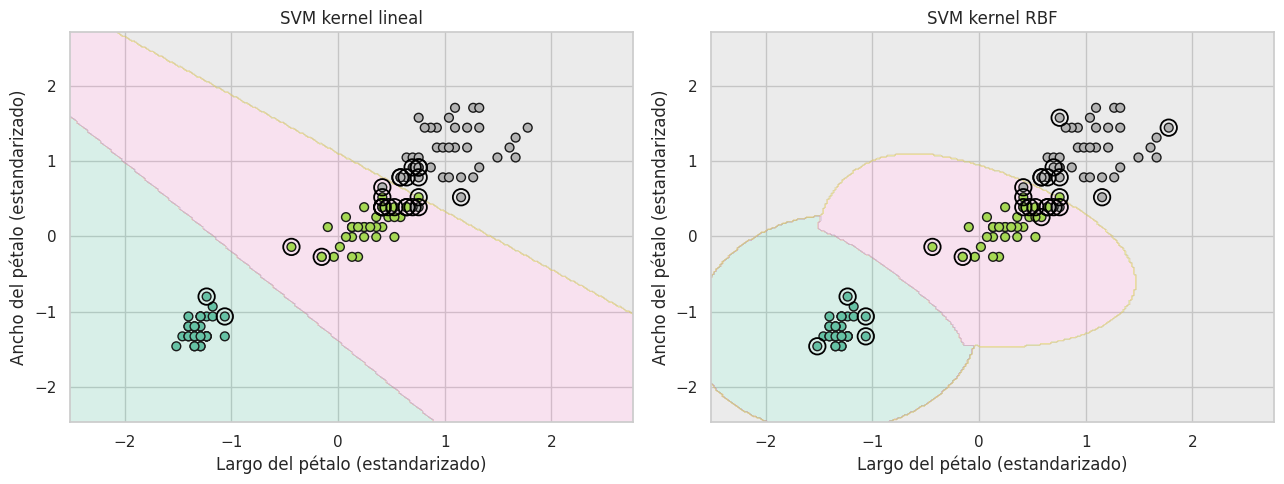

In [21]:
# Seleccionamos únicamente las dos variables del pétalo y las convertimos a arreglo NumPy
X2 = df[["petal length (cm)", "petal width (cm)"]].values
# Dividimos en entrenamiento y prueba igual que antes
X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, y, test_size=0.2, stratify=y, random_state=SEED)
# Creamos un nuevo escalador para estas 2 variables
sc2 = StandardScaler()
# Ajustamos y transformamos el entrenamiento
X2_tr_s = sc2.fit_transform(X2_tr)
# Transformamos la prueba con los parámetros del entrenamiento
X2_te_s = sc2.transform(X2_te)
# Entrenamos una SVM lineal en 2D
svm2_lin = SVC(kernel="linear", C=1).fit(X2_tr_s, y2_tr)
# Entrenamos una SVM RBF en 2D
svm2_rbf = SVC(kernel="rbf", C=1, gamma=1).fit(X2_tr_s, y2_tr)
# Creamos una figura con 2 subgráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# Dibujamos la frontera de la SVM lineal en el primer subgráfico
plot_frontera(svm2_lin, X2_tr_s, y2_tr, axes[0], "SVM kernel lineal")
# Dibujamos la frontera de la SVM RBF en el segundo subgráfico
plot_frontera(svm2_rbf, X2_tr_s, y2_tr, axes[1], "SVM kernel RBF")
# Ajustamos los márgenes para evitar solapamientos
plt.tight_layout()
# Mostramos la figura
plt.show()

### Efecto del hiperparámetro `C`

Observa cómo cambia la frontera y la cantidad de vectores de soporte al variar `C` (kernel lineal).

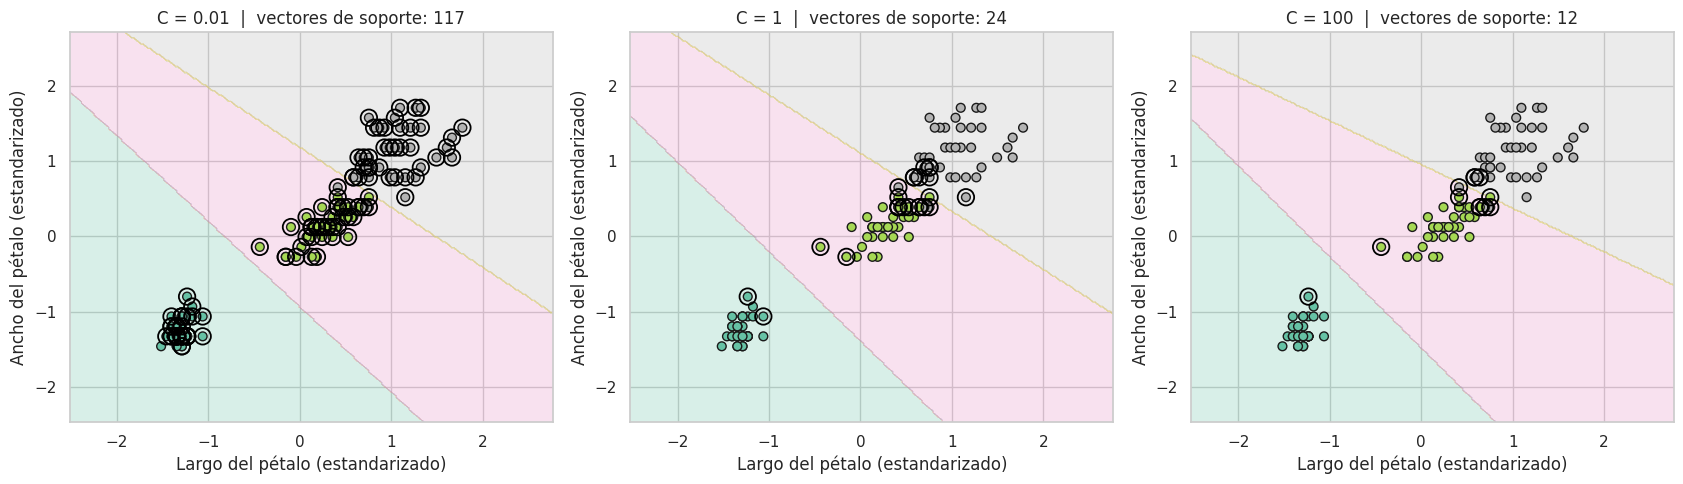

In [22]:
# Definimos los valores de C que queremos comparar
valores_C = [0.01, 1, 100]
# Creamos una figura con 3 subgráficos en una fila
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
# Recorremos cada valor de C junto con su eje correspondiente
for C, ax in zip(valores_C, axes):
    # Entrenamos una SVM lineal con el valor de C actual
    m = SVC(kernel="linear", C=C).fit(X2_tr_s, y2_tr)
    # Dibujamos su frontera e indicamos en el título C y el número de vectores de soporte
    plot_frontera(m, X2_tr_s, y2_tr, ax, f"C = {C}  |  vectores de soporte: {m.n_support_.sum()}")
# Ajustamos los márgenes
plt.tight_layout()
# Mostramos la figura
plt.show()

> Con `C` **pequeño** el margen es amplio y hay más vectores de soporte (más tolerancia a errores). Con `C` **grande** el margen se estrecha para clasificar bien cada punto de entrenamiento.

## 4.9 Comparación práctica: SVM vs. Perceptrón

Comparamos ambos modelos en dos escenarios:

1. **Iris** (4 variables): problema casi linealmente separable.
2. **`make_moons`**: dataset sintético **no lineal** (dos "lunas"), donde el perceptrón lineal está limitado.

In [28]:
# Creamos un Perceptrón con máximo 1000 iteraciones y semilla fija
perceptron = Perceptron(max_iter=1000, random_state=SEED)
# Entrenamos el perceptrón con los datos de Iris escalados
perceptron.fit(X_train_s, y_train)
# Calculamos la exactitud del perceptrón en el set de prueba
acc_perc = accuracy_score(y_test, perceptron.predict(X_test_s))
# Calculamos la exactitud de la mejor SVM en el set de prueba
acc_svm = accuracy_score(y_test, mejor_modelo.predict(X_test_s))
# Mostramos la exactitud del perceptrón
print(f"Accuracy Perceptrón (Iris): {acc_perc:.3f}")
# Mostramos la exactitud de la SVM
print(f"Accuracy SVM        (Iris): {acc_svm:.3f}")

Accuracy Perceptrón (Iris): 0.867
Accuracy SVM        (Iris): 0.967


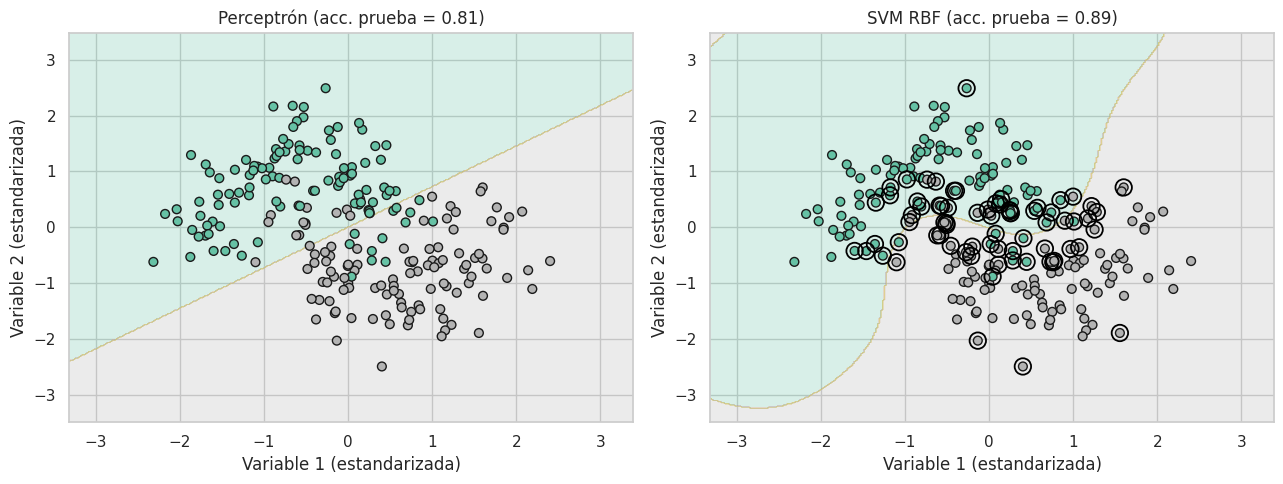

In [24]:
# Generamos 300 puntos con forma de dos lunas entrelazadas y algo de ruido
Xm, ym = make_moons(n_samples=300, noise=0.25, random_state=SEED)
# Dividimos el dataset de lunas en entrenamiento y prueba
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.25, random_state=SEED, stratify=ym)
# Estandarizamos las variables
sc_m = StandardScaler()
# Ajustamos y transformamos el entrenamiento
Xm_tr_s = sc_m.fit_transform(Xm_tr)
# Transformamos la prueba
Xm_te_s = sc_m.transform(Xm_te)
# Entrenamos un perceptrón (frontera lineal) sobre las lunas
perc_m = Perceptron(max_iter=1000, random_state=SEED).fit(Xm_tr_s, ym_tr)
# Entrenamos una SVM con kernel RBF (frontera no lineal) sobre las lunas
svm_m = SVC(kernel="rbf", C=1, gamma="scale").fit(Xm_tr_s, ym_tr)
# Creamos una figura con 2 subgráficos
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# Dibujamos la frontera del perceptrón e incluimos su accuracy en el título
plot_frontera(perc_m, Xm_tr_s, ym_tr, axes[0], f"Perceptrón (acc. prueba = {perc_m.score(Xm_te_s, ym_te):.2f})")
# Dibujamos la frontera de la SVM RBF e incluimos su accuracy en el título
plot_frontera(svm_m, Xm_tr_s, ym_tr, axes[1], f"SVM RBF (acc. prueba = {svm_m.score(Xm_te_s, ym_te):.2f})")
# Cambiamos las etiquetas de ejes porque aquí no son pétalos
for ax in axes:
    # Etiqueta del eje X
    ax.set_xlabel("Variable 1 (estandarizada)")
    # Etiqueta del eje Y
    ax.set_ylabel("Variable 2 (estandarizada)")
# Ajustamos los márgenes
plt.tight_layout()
# Mostramos la figura
plt.show()

> **Conclusión:** el perceptrón solo puede trazar una **línea recta**, por lo que no captura la forma curva de las lunas. La SVM con kernel RBF traza una frontera **no lineal** y obtiene mejor desempeño.

## 4.10 Despliegue: pipeline final y predicción con datos nuevos

Para usar el modelo en producción conviene empaquetar **escalado + SVM** en un único objeto `Pipeline`, de modo que los datos nuevos se procesen exactamente igual que los de entrenamiento. Luego lo guardamos en un archivo con `joblib`.

In [26]:
# Construimos el pipeline final: primero escala los datos y luego aplica la SVM con los mejores hiperparámetros
pipeline_final = Pipeline([
    # Paso 1: estandarización de las variables
    ("scaler", StandardScaler()),
    # Paso 2: SVM con los hiperparámetros ganadores de GridSearchCV (** desempaqueta el diccionario)
    ("svm", SVC(**grid.best_params_, random_state=SEED)),
])
# Entrenamos todo el pipeline con los datos originales (sin escalar) de entrenamiento
pipeline_final.fit(X_train, y_train)
# Evaluamos el pipeline sobre los datos de prueba originales (el pipeline escala internamente)
print(f"Accuracy del pipeline final en prueba: {pipeline_final.score(X_test, y_test):.3f}")
# Guardamos el pipeline entrenado en un archivo .joblib
joblib.dump(pipeline_final, "modelo_svm_iris.joblib")
# Confirmamos que el archivo se guardó
print(" Modelo guardado como 'modelo_svm_iris.joblib'")

Accuracy del pipeline final en prueba: 0.967
 Modelo guardado como 'modelo_svm_iris.joblib'


In [27]:
# Cargamos el modelo guardado desde el archivo (simula usarlo en otro programa)
modelo_cargado = joblib.load("modelo_svm_iris.joblib")
# Creamos una flor nueva con sus 4 medidas (sépalo largo/ancho, pétalo largo/ancho) como DataFrame
nueva_flor = pd.DataFrame([[5.9, 3.0, 5.1, 1.8]], columns=feature_names)
# Predecimos la clase numérica de la flor nueva
clase = modelo_cargado.predict(nueva_flor)[0]
# Traducimos el número de clase al nombre de la especie
print("Especie predicha:", iris.target_names[clase])
# Calculamos la distancia con signo a cada frontera de decisión (confianza relativa de la predicción)
print("Función de decisión:", modelo_cargado.decision_function(nueva_flor).round(3))

Especie predicha: virginica
Función de decisión: [[-0.237  1.184  2.184]]


---
# 5. Conclusiones

- La **SVM** busca el hiperplano de **margen máximo**; solo los **vectores de soporte** determinan la frontera.
- El parámetro **`C`** equilibra el tamaño del margen y los errores; **`kernel`** y **`gamma`** permiten fronteras **no lineales**.
- Es **imprescindible escalar** las variables y evitar *data leakage* (ajustar el escalador solo con entrenamiento).
- Los hiperparámetros se eligen con **validación cruzada** (`GridSearchCV`), y el modelo final se evalúa **una sola vez** en el conjunto de prueba.
- Frente al **perceptrón**, la SVM ofrece solución única, mejor generalización y manejo de datos no lineales mediante kernels.
- Empaquetar el modelo en un `Pipeline` facilita su **despliegue** y reutilización.

##  Referencias

- Cortes, C. & Vapnik, V. (1995). *Support-vector networks*. Machine Learning, 20, 273–297.
- Documentación de scikit-learn: <https://scikit-learn.org/stable/modules/svm.html>
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow*. O'Reilly.